<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🎯 Scoping：structured output 当 router，`Command` 一步路由 + 更新

**一句话定位**：研究前先用**一次 structured output 调用**判断「信息够不够」，够就写 research brief，不够就把问题当 AIMessage 发回去等下一轮 —— 这是整门课最便宜、却最能防止「研究跑偏」的一步。
> 对应主课 `1_a_🔥_scoping.ipynb`；本机 langgraph 1.2.0 / langchain 1.3.1 核对，API 无变化。

</div>

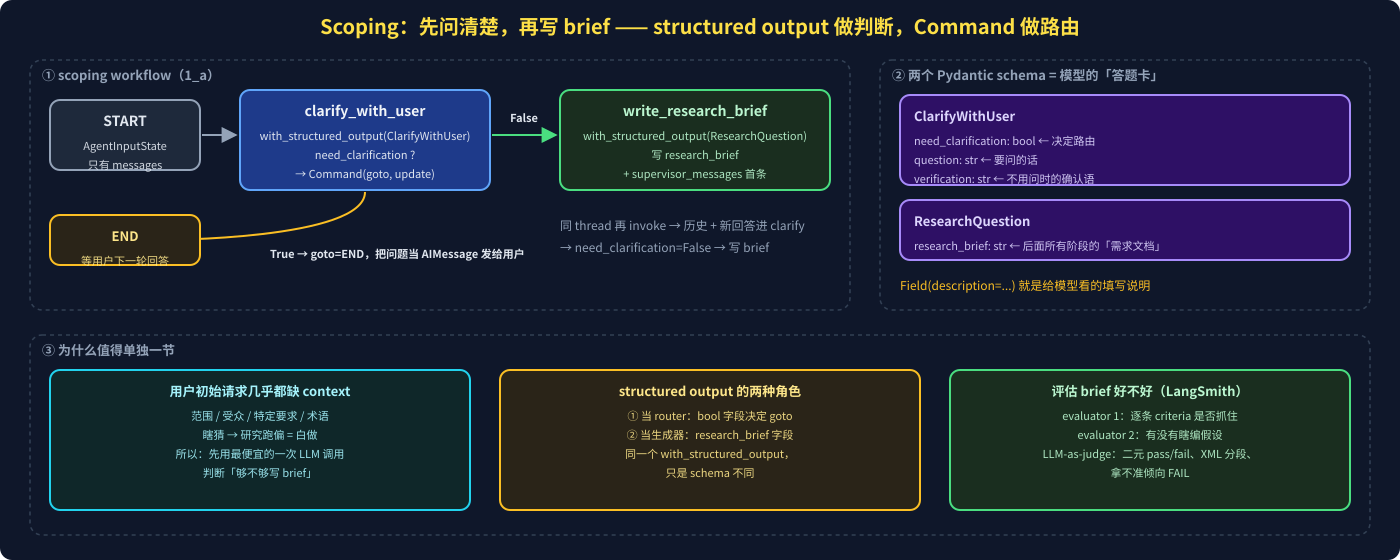

In [ ]:
from IPython.display import SVG
SVG(filename="assets/01_scoping.svg")

### 1️⃣ 两个节点、两个 schema、一个 `Command`

| 节点 | 调用 | schema 里关键字段 | 返回 |
|---|---|---|---|
| `clarify_with_user` | `model.with_structured_output(ClarifyWithUser).invoke([HumanMessage(prompt)])` | `need_clarification: bool` | `Command(goto=END, update={"messages": [AIMessage(question)]})` 或 `Command(goto="write_research_brief", update={"messages": [AIMessage(verification)]})` |
| `write_research_brief` | `model.with_structured_output(ResearchQuestion).invoke(...)` | `research_brief: str` | 普通 dict：`{"research_brief": ..., "supervisor_messages": [HumanMessage(brief)]}` |

两点手法：
- **prompt 里塞整段对话**：`get_buffer_string(state["messages"])` 把 messages 列表压成 `Human: ... / AI: ...` 文本，再放进 `{messages}` 占位 —— 模型看到完整上下文才能判断缺什么。
- **把问题当 AIMessage 写回 `messages`**：下一轮用户回答进来时，同一 thread 的历史自然包含「问 + 答」，`clarify_with_user` 再跑一次就会判为够了。所以这个 workflow 必须配 **checkpointer + thread_id** 才能多轮。

### 2️⃣ `AgentInputState` vs `AgentState`：接口隔离

In [ ]:
from langgraph.graph import MessagesState, StateGraph

class AgentInputState(MessagesState):        # 对外接口：只收 messages
    pass

class AgentState(MessagesState):             # 内部状态：多了研究阶段的字段
    research_brief: str | None
    supervisor_messages: ...
    raw_notes: ...
    notes: ...
    final_report: str

builder = StateGraph(AgentState, input_schema=AgentInputState)   # 1.x 写法；0.5 起 input= 弃用

调用方只能传 `messages`，内部字段（brief / notes / report）**由图自己产生**，外部既不能也不需要伪造。`1_b_⭐️_AgentInputState接口隔离.ipynb` 用餐厅类比讲透了这件事。

### 3️⃣ 评估 brief：两个 evaluator

| evaluator | 问什么 | 实现 |
|---|---|---|
| `evaluate_success_criteria` | 人工写的每条 criteria 是否被 brief 抓住 | 对**每条** criteria 单独调一次 `with_structured_output(Criteria)`，`score = 抓住数 / 总数`，逐条理由放 `extra` |
| `evaluate_no_assumptions` | brief 有没有加用户没说的假设 | 一次调用，`score = 1.0 / 0.0`，理由放 `comment` |

`langsmith_client.evaluate(target_func, data=dataset_name, evaluators=[...], experiment_prefix=...)`：`target_func` 每次用新的 `thread_id`，避免 dataset 里两条对话串线。
写 judge prompt 的 7 条（Hamel Husain）：明确角色、二元 pass/fail、给领域 context、XML 分段、正反例各 3–4 个、输出指令、拿不准倾向 FAIL。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**🆕 2026-10 对照**

- `with_structured_output` / `Command` / `input_schema=` / `langsmith.evaluate` 全部未变；deepagents 的官方 deep research 例子**没有**单独的 scoping 节点，而是 prompt 要求「先把请求写进 `/research_request.md`，不清楚就直接问」—— 本课把这一步显式建模成节点，**可测、可评估**，仍是更稳的做法。
- 想省 evaluator 代码：`openevals.create_llm_as_judge`；但本课「逐条 criteria 单独打分」的粒度更细。

</div>

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| 没 checkpointer / 换了 thread_id 再 invoke | 第二轮看不到第一轮的问答，永远在问 |
| `Command(goto=END)` 时忘了 `update` messages | 用户收不到问题，图静默结束 |
| schema 的 `description` 写得含糊 | 模型乱填 `need_clarification`，路由随机 |
| evaluator 返回了 schema 外的 key | LangSmith 报 `EvaluationResult` 校验错；逐条细节放 `extra` |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：scoping = **一次 structured output 当 router**（`need_clarification` 决定 `Command.goto`）+ **一次 structured output 当生成器**（`research_brief`）；对外只暴露 `AgentInputState.messages`，多轮靠 checkpointer，好坏靠两个 LLM-as-judge 量出来。

</div>